# Textual skill churn

This continues the evolution pilot. The GitHub API gives the number of lines added and removed in each commit for each `SKILL.md`. Here we plot those counts for the same ten skills.

## Load the history

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

file = Path("../data/gitskills/evolution_pilot.json")
if not file.exists():
    file = Path("data/gitskills/evolution_pilot.json")

history = pd.read_json(file, convert_dates=["committed_at"])
history = history.sort_values(["repo_full_name", "path", "committed_at"]).reset_index(drop=True)
history[["name", "repo_full_name", "path", "committed_at"]].head()

,name,repo_full_name,path,committed_at
0,next-task,Chris-Graffagnino/creance,.claude/skills/next-task/SKILL.md,2026-06-12 13:10:45+00:00
1,next-task,Chris-Graffagnino/creance,.claude/skills/next-task/SKILL.md,2026-06-12 14:40:06+00:00
2,next-task,Chris-Graffagnino/creance,.claude/skills/next-task/SKILL.md,2026-06-12 19:31:59+00:00
3,next-task,Chris-Graffagnino/creance,.claude/skills/next-task/SKILL.md,2026-06-12 21:06:18+00:00
4,next-task,Chris-Graffagnino/creance,.claude/skills/next-task/SKILL.md,2026-06-12 21:09:56+00:00


## Calculate churn

The JSON already has `additions` and `deletions` for the `SKILL.md` in each commit. Churn is their sum. A rewritten line usually counts as one deletion and one addition.

In [7]:
changes = history.copy()
changes["skill"] = changes["name"].fillna(changes["path"].str.split("/").str[-2])
changes["churn"] = changes["additions"] + changes["deletions"]
changes[["skill", "committed_at", "additions", "deletions", "churn"]].head()

,skill,committed_at,additions,deletions,churn
0,next-task,2026-06-12 13:10:45+00:00,59,0,59
1,next-task,2026-06-12 14:40:06+00:00,6,0,6
2,next-task,2026-06-12 19:31:59+00:00,1,1,2
3,next-task,2026-06-12 21:06:18+00:00,14,0,14
4,next-task,2026-06-12 21:09:56+00:00,7,2,9


## Added and removed lines per commit

Each point is one commit that changed the `SKILL.md`. The counts come from GitHub, including the first commit of each file.

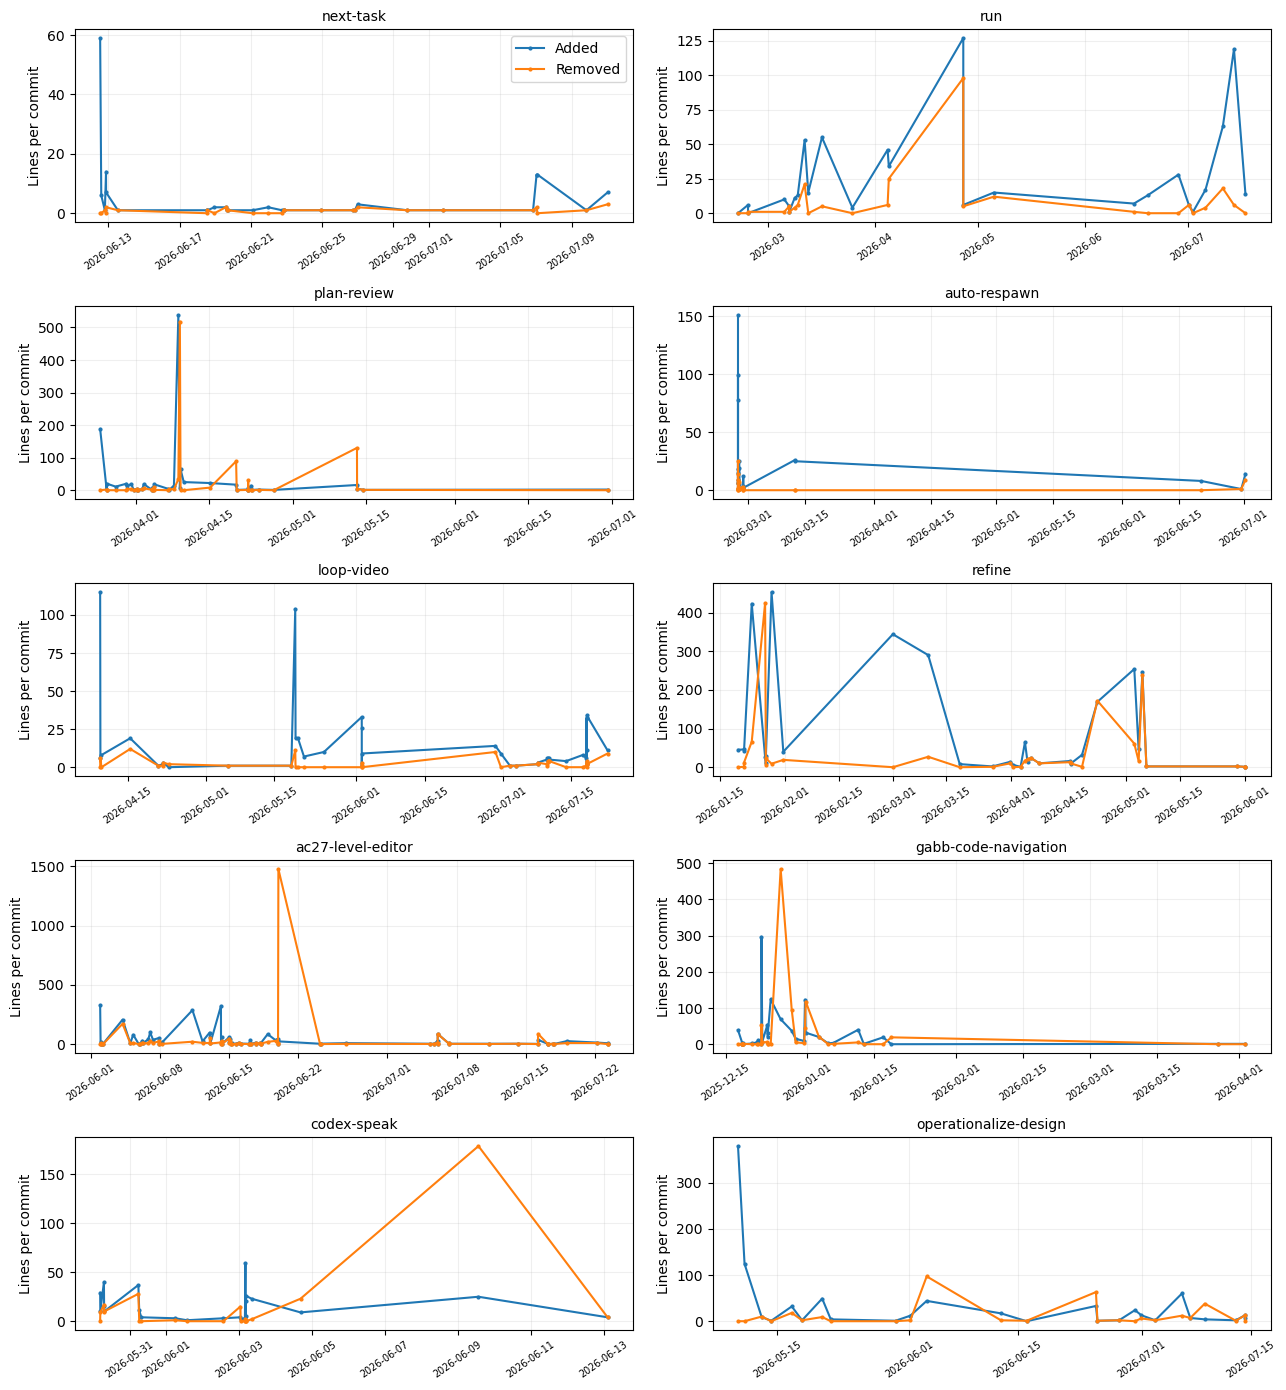

In [10]:
fig, axes = plt.subplots(5, 2, figsize=(13, 14))
for ax, (skill, group) in zip(axes.flat, changes.groupby("skill", sort=False)):
    ax.plot(group["committed_at"], group["additions"], marker="o", markersize=2, label="Added")
    ax.plot(group["committed_at"], group["deletions"], marker="o", markersize=2, label="Removed")
    ax.set_title(skill, fontsize=10)
    ax.set_ylabel("Lines per commit")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelrotation=35, labelsize=7)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## Commits with the most churn

These are candidates for closer reading. A large change may reflect a rewrite, reordering, or deletion. the line count alone does not tell us why it happened.

In [9]:
largest = changes.nlargest(15, "churn").copy()
largest["subject"] = largest["message"].str.split("\n").str[0]
largest["commit_url"] = "https://github.com/" + largest["repo_full_name"] + "/commit/" + largest["commit_sha"]
largest[["skill", "committed_at", "additions", "deletions", "churn", "subject", "commit_url"]]

,skill,committed_at,additions,deletions,churn,subject,commit_url
237,ac27-level-editor,2026-06-19 23:36:42+00:00,24,1476,1500,@,https://github.com/ericpzh/AC27LevelEditor/com...
75,plan-review,2026-04-09 02:42:07+00:00,538,34,572,Refactor code structure for improved readabili...,https://github.com/Wilder1222/superomni/commit...
276,gabb-code-navigation,2025-12-26 10:43:38+00:00,69,484,553,refactor(skill): restructure SKILL.md for bett...,https://github.com/gabb-software/gabb-cli/comm...
76,plan-review,2026-04-09 09:39:53+00:00,8,518,526,Refactor code structure for improved readabili...,https://github.com/Wilder1222/superomni/commit...
162,refine,2026-01-23 04:34:32+00:00,423,66,489,feat(claude): enhance BA skills and add web-de...,https://github.com/duc01226/EasyPlatform/commi...
185,refine,2026-05-05 04:43:44+00:00,245,239,484,chore(skills): harden layout tooling — fence-b...,https://github.com/duc01226/EasyPlatform/commi...
166,refine,2026-01-28 08:39:10+00:00,453,9,462,refactor(claude): consolidate skills with inli...,https://github.com/duc01226/EasyPlatform/commi...
163,refine,2026-01-26 16:22:44+00:00,26,425,451,refactor(skills): comprehensive skills review ...,https://github.com/duc01226/EasyPlatform/commi...
195,ac27-level-editor,2026-06-04 05:27:05+00:00,207,172,379,refactor: comprehensive React best-practices a...,https://github.com/ericpzh/AC27LevelEditor/com...
314,operationalize-design,2026-05-09 22:53:28+00:00,379,0,379,Update datetime examples and test status repor...,https://github.com/keturk/datrix/commit/8184c3...


## What we see

We can now locate sudden additions and deletions in the ten selected files. The next step is to analyze the commit messages separately for the skills with the most churns.